## Part 1

#### Import

In [13]:
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

#### Part a

##### Random Walk Metropolis Function

In [14]:
# Let f(x) = 0.5 * exp(-abs(x)) 
# Log-density Fn: log f(x) = log(0.5) - abs(x)
def log_f(x):
    """
    Computes the log-density of the target distribution up to a constant.
    """
    return -np.abs(x)

def rwm_sampler(x0, N, s):
    """
    Random Walk Metropolis-Hastings sampler.
    """
    chain = np.zeros(N + 1)
    chain[0] = x0
    xi_minus_1 = x0
    
    for i in range(N):
        # Proposal: N(xi-1, s^2)
        x_star = norm.rvs(loc=xi_minus_1, scale=s)
        
        # Log Acceptance Ratio
        log_ratio = log_f(x_star) - log_f(xi_minus_1)
        
        # log(runif(1))
        log_u = np.log(np.random.uniform(0, 1))
        
        # Acceptance Criterion
        if log_u < log_ratio:
            xi = x_star
        else:
            xi = xi_minus_1
            
        chain[i + 1] = xi
        xi_minus_1 = xi
        
    # Return samples (x1,...,xN), excluding initial x0
    return chain[1:]

##### Gelman-Rubin (R-hat) Function using Pandas

In [15]:
def calculate_R_pandas(chains):
    """
    Calculates the Gelman-Rubin convergence diagnostic R = (B+W)/W.
    """
    # Convert list of chains into a DataFrame (columns as chains, rows as iterations)
    df = pd.DataFrame(np.array(chains).T)

    J = df.shape[1] # No of chains (columns)
    N = df.shape[0] # No of samples (rows)

    if J < 2:
        return np.nan

    M_j = df.mean() # Mean of ea chain
    V_j = df.var() # Var of each chain

    W = V_j.mean() # Within-chain variance
    M = M_j.mean() # Overall mean

    # B: Between-chain variance
    B = (N / (J-1)) * ((M-J - M)**2).sum()

    R = (B + W) / W

    return R

##### Sampling, Statistics & Visuals

--- Part A: Sampling & Statistics ---
Sample Mean; -0.0516
Sample Standard Deviation: 1.3580


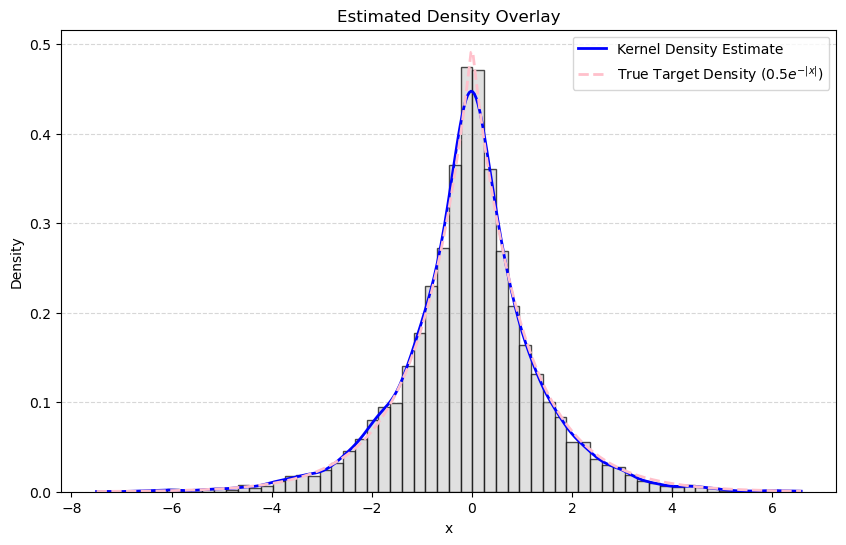

In [16]:
from scipy.stats import gaussian_kde, norm

N_a = 10001
s_a = 1.0
x0_a = 5.0

# Generating samples
sample_a = rwm_sampler(x0=x0_a, N=N_a, s=s_a)

sample_mean = np.mean(sample_a)
sample_sd = np.std(sample_a, ddof=1) 

print("--- Part A: Sampling & Statistics ---")
print(f"Sample Mean; {sample_mean:.4f}")
print(f"Sample Standard Deviation: {sample_sd:.4f}")

# Single Step Test
N_chck = 10001
s_check = 1.0
x0_check = 0.0

x_star = norm.rvs(loc=x0_check, scale=s_check)
log_ratio = log_f(x_star) - log_f(x0_check)
log_u = np.log(np.random.uniform(0,1))

if log_u < log_ratio:
    x0_check = x_star

# Visualisation
plt.figure(figsize=(10,6))

# Histogram
plt.hist(sample_a, bins=60, density=True, color='lightgrey', edgecolor='black', alpha=0.7)

# Calculate KDE
kde = gaussian_kde(sample_a)
z = np.linspace(np.min(sample_a), np.max(sample_a), 400)

# Plot Kernel Density Plot
plt.plot(z, kde.evaluate(z),
         color='blue',
         linewidth=2,
         label= "Kernel Density Estimate")

# Plot f(x) = 0.5 * exp(-abs(x)) 
true_density = 0.5 * np.exp(-np.abs(z))
plt.plot(z, true_density,
         color='pink',
         linewidth = 2,
         linestyle= '--',
         label = "True Target Density ($0.5e^{-|x|}$)")

plt.title("Estimated Density Overlay")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.5, linestyle= '--')
plt.show()
    

#### Part b

In [17]:
N_fixed = 2000
J_fixed = 4
x0_fixed = np.array([-30.0, -15.0, 15.0, 30.0])

# Definition of grid of standard deviation (s)
s_grid = np.linspace(0.001, 1.0, 1000)

R_values_s_grid = np.zeros(len(s_grid))

# R for specified s
s_b = 0.001
chains_b = [rwm_sampler(x0=x0, N=N_fixed, s=s_b) for x0 in x0_fixed]
R_value_specific = calculate_R_pandas(chains_b)

print("\n---Part B: R-Value Calculation ---")
print(f"R value for specific s={s_b}: {R_value_specific:.4f}")

# R Grid search
for k, s_current in enumerate(s_grid):
    # Generate chains for current s
    chains_current = [rwm_sampler(x0=x0, N=N_fixed, s=s_current) for x0 in x0_fixed]

    R_values_s_grid[k] = calculate_R_pandas(chains_current)

# Find the specific R-hat value that corresponds to the optimal 's'
min_R_hat = np.min(R_values_s_grid)

print("-" * 30)
print(f"RESULTS FOR PART B:")
print(f"Optimal Proposal Step (s): {s_optimal:.4f}")
print(f"Best R-hat Value reached:   {min_R_hat:.4f}")
print("-" * 30)

# Find optimal s
s_optimal = s_grid[np.argmin(R_values_s_grid)]
min_R = np.min(R_values_s_grid)

print(f"Optimal s found: {s_optimal:.3f}")
print(f"Minimum R value at optimal s: {min_R:.4f}")



---Part B: R-Value Calculation ---
R value for specific s=0.001: 31793337.3700
------------------------------
RESULTS FOR PART B:
Optimal Proposal Step (s): 0.2600
Best R-hat Value reached:   135.5242
------------------------------
Optimal s found: 0.239
Minimum R value at optimal s: 135.5242


#### Plot Histogram

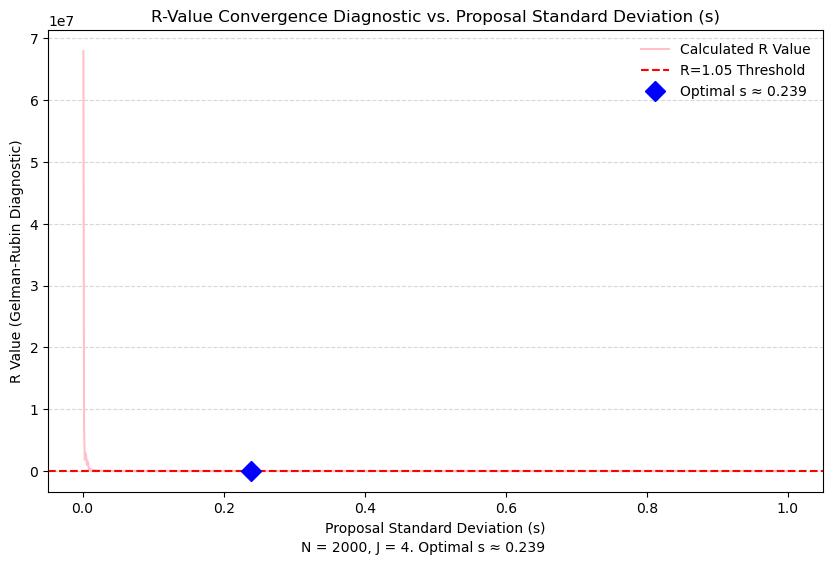

In [18]:

# Visualisation of R vs s
plt.figure(figsize=(10,6))

# Plot R values
plt.plot(s_grid, R_values_s_grid,
         linestyle='-',
         color='pink', 
         linewidth=1.5,
         label="Calculated R Value")

# Add convergence threshold (abline(h = 1.05) in R)
plt.axhline(y=1.05,
            color='red',
            linestyle='--',
            linewidth=1.5,
            label="R=1.05 Threshold")

# Highlight optimal s value (points() in R)
optimal_R_value = R_values_s_grid[np.argmin(R_values_s_grid)]
plt.plot(s_optimal, optimal_R_value,
         marker='D', # Diamond marker
         markersize=10,
         color='blue',
         linestyle='None',
         label=f"Optimal s ≈ {s_optimal:.3f}")

plt.title("R-Value Convergence Diagnostic vs. Proposal Standard Deviation (s)")
plt.xlabel("Proposal Standard Deviation (s)")
plt.ylabel("R Value (Gelman-Rubin Diagnostic)")

# Subtitle (sub in R)
plt.figtext(0.5, 0.01, f"N = {N_fixed}, J = {J_fixed}. Optimal s ≈ {s_optimal:.3f}",
            wrap=True, horizontalalignment='center', fontsize=10)

plt.legend(loc="upper right", frameon=False)
plt.grid(axis='y', alpha=0.5, linestyle='--')
plt.show()